
# 07 — Comparative Evaluation of Object Detection Models

## Aim

To systematically compare YOLOv8n, RetinaNet ResNet50-FPN V2
and Faster R-CNN ResNet50-FPN V2 for detecting and localising
pork rasher packaging defects.

## Objectives

1. Load the best validation checkpoints from the three models.
2. Evaluate all models on the same four-class dataset.
3. Compare mAP@50, mAP@50:95 and per-class average precision.
4. Analyse precision, recall, micro-F1 and macro-F1 across
   confidence thresholds.
5. Compare raw and normalised confusion matrices.
6. Measure parameter counts, inference speed, FPS and GPU memory.
7. Investigate the detection-performance versus computational-cost
   trade-off.
8. Conduct final evaluation on the held-out test dataset.

## Models

- YOLOv8n — lightweight one-stage detector
- RetinaNet ResNet50-FPN V2 — anchor-based one-stage detector
- Faster R-CNN ResNet50-FPN V2 — two-stage detector

## Defect Classes

1. loose-meat
2. packaging-error
3. twisted-meat
4. unsealed

## Evaluation Methodology

All models are evaluated on identical images using the same
ground-truth annotations and a common evaluation implementation.

Model-specific preprocessing and postprocessing are documented,
as they may affect detection results and inference performance.

Confidence thresholds are selected using validation data only.
The test dataset remains untouched until model selection is complete.



## 1. Environment Setup

The required libraries are imported and Google Drive is mounted.

The three models are evaluated using the same computing environment,
with GPU acceleration enabled where available.

A fixed random seed is used for reproducibility. No further
model training or weight optimisation is performed in this notebook.


In [ ]:

%pip install -q ultralytics torchmetrics pycocotools pandas matplotlib

from google.colab import drive
drive.mount("/content/gdrive_new")

from pathlib import Path
from functools import partial
from PIL import Image

import gc
import json
import random
import time
import shutil

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn

from ultralytics import YOLO

from torchvision.transforms import functional as TF
from torchvision.ops import box_iou

from torchvision.models.detection import (
    retinanet_resnet50_fpn_v2,
    fasterrcnn_resnet50_fpn_v2
)

from torchvision.models.detection.retinanet import (
    RetinaNetClassificationHead
)

from torchvision.models.detection.faster_rcnn import (
    FastRCNNPredictor
)

from torchmetrics.detection.mean_ap import (
    MeanAveragePrecision
)

# Reproducibility
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)
print("PyTorch:", torch.__version__)

if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.0/47.0 kB 1.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 24.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.4/983.4 kB 59.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 98.2/98.2 kB 4.7 MB/s eta 0:00:00
Mounted at /content/gdrive_new
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Device: cuda
PyTorch: 2.11.0+cu130
GPU: Tesla T4



## 2. Experiment Configuration

The same four-class dataset and model checkpoints are loaded from
Google Drive.

The output directory is kept separate from the individual model
training runs.

All ground-truth annotations are converted from YOLO's normalised
bounding-box format to absolute xyxy coordinates.

The following class convention is used in the common evaluator:

- 0: loose-meat
- 1: packaging-error
- 2: twisted-meat
- 3: unsealed

Torchvision's original prediction labels are shifted from 1–4
to 0–3 before evaluation.

This prevents label-indexing differences from affecting the results.


In [ ]:

# ----------------------------------------
# Project paths
# ----------------------------------------
PROJECT_ROOT = Path(
    "/content/gdrive_new/MyDrive/MMA3001_Project"
)

DATASET_ROOT = (
    PROJECT_ROOT /
    "dataset/pork_rasher_v4_4class"
)

RUNS_ROOT = PROJECT_ROOT / "model_runs"

OUTPUT_DIR = (
    PROJECT_ROOT / "comparison_results"
)

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

# ----------------------------------------
# Model checkpoint paths
# ----------------------------------------
YOLO_PATH = (
    RUNS_ROOT /
    "yolov8n_4class_30epochs/weights/best.pt"
)

RETINANET_PATH = (
    RUNS_ROOT /
    "retinanet_resnet50_4class/best.pt"
)

FASTER_RCNN_PATH = (
    RUNS_ROOT /
    "faster_rcnn_resnet50_4class/best.pt"
)

MODEL_NAMES = [
    "YOLOv8n",
    "RetinaNet",
    "Faster R-CNN"
]

CLASS_NAMES = [
    "loose-meat",
    "packaging-error",
    "twisted-meat",
    "unsealed"
]

NUM_CLASSES = len(CLASS_NAMES)

# ----------------------------------------
# Evaluation settings
# ----------------------------------------
IMAGE_SIZE = 640
MATCH_IOU = 0.50

# Broad threshold comparison
THRESHOLDS = [
    0.10, 0.25, 0.50, 0.70, 0.849
]

# Fine threshold optimisation
FINE_THRESHOLDS = np.round(
    np.arange(0.10, 0.5001, 0.025),
    3
)

# Use validation until final evaluation is authorised
RUN_FINAL_TEST = False

# ----------------------------------------
# Verify dataset and checkpoints
# ----------------------------------------
assert DATASET_ROOT.exists(), (
    f"Dataset not found: {DATASET_ROOT}"
)

checkpoint_paths = {
    "YOLOv8n": YOLO_PATH,
    "RetinaNet": RETINANET_PATH,
    "Faster R-CNN": FASTER_RCNN_PATH
}

for name, path in checkpoint_paths.items():
    print(f"{name}: {path.exists()}")

    if not path.exists():
        print("Missing:", path)

assert all(
    path.exists()
    for path in checkpoint_paths.values()
), "One or more checkpoints are missing."

print("\nOutput directory:", OUTPUT_DIR)


YOLOv8n: True
RetinaNet: True
Faster R-CNN: True

Output directory: /content/gdrive_new/MyDrive/MMA3001_Project/comparison_results



## 3. Standardised Dataset Preparation

The four-class validation dataset is loaded using identical image
files and annotation labels for all three object detectors.

YOLO annotations are converted from normalised centre coordinates,
width and height into absolute xyxy coordinates.

The original image dimensions are retained for ground-truth
bounding boxes.

The data are read once and reused for all models to prevent
differences in file ordering or annotation conversion.


In [ ]:

def load_dataset(split):
    """
    Load image paths and ground-truth annotations.

    Args:
        split: 'valid' or 'test'

    Returns:
        image_paths
        targets

    Target format:
        boxes: FloatTensor [N, 4] in xyxy
        labels: LongTensor [N] using IDs 0-3
    """

    images_dir = (
        DATASET_ROOT / split / "images"
    )

    labels_dir = (
        DATASET_ROOT / split / "labels"
    )

    assert images_dir.exists()
    assert labels_dir.exists()

    image_paths = sorted([
        p for p in images_dir.iterdir()
        if p.suffix.lower() in {
            ".jpg", ".jpeg", ".png", ".webp"
        }
    ])

    targets = []

    for image_path in image_paths:

        with Image.open(image_path) as image:
            width, height = image.size

        label_path = (
            labels_dir /
            f"{image_path.stem}.txt"
        )

        boxes = []
        labels = []

        if label_path.exists():

            for line in label_path.read_text().splitlines():

                if not line.strip():
                    continue

                values = list(
                    map(float, line.split())
                )

                if len(values) != 5:
                    raise ValueError(
                        f"Invalid annotation: {label_path}"
                    )

                class_id = int(values[0])

                if not 0 <= class_id < NUM_CLASSES:
                    raise ValueError(
                        f"Invalid class: {label_path}"
                    )

                xc, yc, bw, bh = values[1:]

                x1 = (xc - bw / 2) * width
                y1 = (yc - bh / 2) * height
                x2 = (xc + bw / 2) * width
                y2 = (yc + bh / 2) * height

                x1 = max(0, min(x1, width))
                y1 = max(0, min(y1, height))
                x2 = max(0, min(x2, width))
                y2 = max(0, min(y2, height))

                if x2 <= x1 or y2 <= y1:
                    raise ValueError(
                        f"Invalid bounding box: {label_path}"
                    )

                boxes.append([x1, y1, x2, y2])
                labels.append(class_id)

        targets.append({
            "boxes": torch.tensor(
                boxes,
                dtype=torch.float32
            ).reshape(-1, 4),

            "labels": torch.tensor(
                labels,
                dtype=torch.int64
            )
        })

    return image_paths, targets


# Only load validation set for now
valid_image_paths, valid_targets = (
    load_dataset("valid")
)

print("Validation images:", len(valid_image_paths))

assert len(valid_image_paths) == len(valid_targets)
assert len(valid_image_paths) > 0

# Verify class counts
class_counts = np.zeros(NUM_CLASSES, dtype=int)

for target in valid_targets:
    for label in target["labels"]:
        class_counts[int(label)] += 1

print("\nValidation annotations:")

for name, count in zip(CLASS_NAMES, class_counts):
    print(f"{name}: {count}")


Validation images: 120

Validation annotations:
loose-meat: 3
packaging-error: 34
twisted-meat: 3
unsealed: 81



## 4. Load Trained Object Detection Models

The best validation checkpoint for each detector is loaded.

The three architectures are reconstructed using their original
training configurations before loading their saved weights.

YOLOv8n is loaded through Ultralytics, while RetinaNet and
Faster R-CNN are reconstructed using Torchvision.

All models are placed in evaluation mode to disable training
behaviour such as gradient updates.

No additional training is performed.


In [ ]:

# ----------------------------------------
# 1. YOLOv8n
# ----------------------------------------
yolo_model = YOLO(str(YOLO_PATH))

print("YOLO loaded:", YOLO_PATH)
print("YOLO classes:", yolo_model.names)

assert len(yolo_model.names) == NUM_CLASSES


# ----------------------------------------
# 2. RetinaNet ResNet50-FPN V2
# ----------------------------------------
# Construct architecture without downloading
# pretrained weights again. The checkpoint
# already contains the trained model weights.

retinanet_model = retinanet_resnet50_fpn_v2(
    weights=None,
    weights_backbone=None,
    min_size=640,
    max_size=640
)

# Reconstruct the same classification head
# used in Notebook 05.
in_channels = retinanet_model.backbone.out_channels

num_anchors = (
    retinanet_model.anchor_generator
    .num_anchors_per_location()[0]
)

retinanet_model.head.classification_head = (
    RetinaNetClassificationHead(
        in_channels=in_channels,
        num_anchors=num_anchors,
        num_classes=NUM_CLASSES + 1,
        norm_layer=partial(nn.GroupNorm, 32)
    )
)

retinanet_model.detections_per_img = 100

retina_checkpoint = torch.load(
    RETINANET_PATH,
    map_location="cpu",
    weights_only=False
)

retinanet_model.load_state_dict(
    retina_checkpoint["model_state"],
    strict=True
)

retinanet_model = retinanet_model.to(device)
retinanet_model.eval()

print("\nRetinaNet loaded")
print("Selected epoch:", retina_checkpoint.get("epoch"))


# ----------------------------------------
# 3. Faster R-CNN ResNet50-FPN V2
# ----------------------------------------
faster_model = fasterrcnn_resnet50_fpn_v2(
    weights=None,
    weights_backbone=None,
    min_size=640,
    max_size=640
)

in_features = (
    faster_model.roi_heads.box_predictor
    .cls_score.in_features
)

faster_model.roi_heads.box_predictor = (
    FastRCNNPredictor(
        in_channels=in_features,
        num_classes=NUM_CLASSES + 1
    )
)

# Match original Faster R-CNN experiment
faster_model.roi_heads.score_thresh = 0.001
faster_model.roi_heads.nms_thresh = 0.50
faster_model.roi_heads.detections_per_img = 100

faster_checkpoint = torch.load(
    FASTER_RCNN_PATH,
    map_location="cpu",
    weights_only=False
)

faster_model.load_state_dict(
    faster_checkpoint["model_state"],
    strict=True
)

faster_model = faster_model.to(device)
faster_model.eval()

print("\nFaster R-CNN loaded")
print("Selected epoch:", faster_checkpoint.get("epoch"))

print("\nAll three models successfully loaded.")


YOLO loaded: /content/gdrive_new/MyDrive/MMA3001_Project/model_runs/yolov8n_4class_30epochs/weights/best.pt
YOLO classes: {0: 'loose-meat', 1: 'packaging-error', 2: 'twisted-meat', 3: 'unsealed'}

RetinaNet loaded
Selected epoch: 13

Faster R-CNN loaded
Selected epoch: 3

All three models successfully loaded.



## 5. Standardised Prediction Collection

Each trained detector is used to predict bounding boxes and
class labels for the same validation images.

Model outputs are converted into a common format containing:

- Bounding boxes in absolute xyxy coordinates
- Prediction confidence scores
- Class IDs from 0 to 3

The model-specific postprocessing is retained, including NMS
and internal filtering.

A low initial confidence threshold is used so that predictions
remain available for subsequent precision-recall and confidence
threshold analyses.

Inference outputs are saved to disk so repeated evaluation does
not require rerunning the neural networks.


In [ ]:

# ----------------------------------------
# Shared image loader
# ----------------------------------------
def load_image_tensor(image_path):
    """
    Load image as a float RGB tensor [C,H,W]
    with pixel values between 0 and 1.
    """
    with Image.open(image_path) as image:
        image = image.convert("RGB")
        return TF.to_tensor(image)


# ----------------------------------------
# YOLO inference
# ----------------------------------------
@torch.no_grad()
def predict_yolo(image_paths):

    predictions = []

    results = yolo_model.predict(
        source=[str(p) for p in image_paths],
        imgsz=IMAGE_SIZE,
        conf=0.001,
        iou=0.70,
        max_det=300,
        device=0 if device.type == "cuda" else "cpu",
        stream=True,
        verbose=False
    )

    for result in results:

        boxes = result.boxes

        predictions.append({
            "boxes": boxes.xyxy.detach().cpu(),
            "scores": boxes.conf.detach().cpu(),
            "labels": boxes.cls.detach().cpu().long()
        })

    return predictions


# ----------------------------------------
# Torchvision inference
# ----------------------------------------
@torch.no_grad()
def predict_torchvision(model, image_paths):
    """
    Run inference with RetinaNet or Faster R-CNN.

    Converts labels:
        Model: 1-4
        Common evaluator: 0-3
    """

    model.eval()

    predictions = []

    for image_path in image_paths:

        image = load_image_tensor(
            image_path
        ).to(device)

        outputs = model([image])[0]

        predictions.append({
            "boxes": outputs["boxes"].detach().cpu(),
            "scores": outputs["scores"].detach().cpu(),
            "labels": (
                outputs["labels"].detach().cpu().long() - 1
            )
        })

    return predictions


# ----------------------------------------
# Validate output structure
# ----------------------------------------
def verify_predictions(predictions, targets):

    assert len(predictions) == len(targets)

    for pred in predictions:

        assert pred["boxes"].ndim == 2
        assert pred["boxes"].shape[1] == 4

        assert len(pred["boxes"]) == len(pred["scores"])
        assert len(pred["scores"]) == len(pred["labels"])

        assert torch.isfinite(pred["boxes"]).all()
        assert torch.isfinite(pred["scores"]).all()

        if len(pred["labels"]):
            assert pred["labels"].min() >= 0
            assert pred["labels"].max() < NUM_CLASSES

    print("Prediction format verified.")


In [ ]:

# Collect validation predictions
# This does NOT train the models.

print("Evaluating YOLOv8n...")
pred_yolo = predict_yolo(valid_image_paths)

print("Evaluating RetinaNet...")
pred_retina = predict_torchvision(
    retinanet_model,
    valid_image_paths
)

print("Evaluating Faster R-CNN...")
pred_faster = predict_torchvision(
    faster_model,
    valid_image_paths
)

# Group model predictions
validation_predictions = {
    "YOLOv8n": pred_yolo,
    "RetinaNet": pred_retina,
    "Faster R-CNN": pred_faster
}

# Verify all prediction sets
for name, predictions in validation_predictions.items():

    print(f"\n{name}")

    verify_predictions(
        predictions,
        valid_targets
    )

    total_boxes = sum(
        len(p["boxes"])
        for p in predictions
    )

    print("Returned predictions:", total_boxes)


# Save for reproducibility
# Only load these files if they come from your own
# trusted experiments.
torch.save(
    {
        "image_names": [
            p.name for p in valid_image_paths
        ],
        "predictions": validation_predictions,
        "targets": valid_targets
    },
    OUTPUT_DIR / "validation_predictions.pt"
)

print("\nValidation predictions saved.")


Evaluating YOLOv8n...
Evaluating RetinaNet...
Evaluating Faster R-CNN...

YOLOv8n
Prediction format verified.
Returned predictions: 1368

RetinaNet
Prediction format verified.
Returned predictions: 1442

Faster R-CNN
Prediction format verified.
Returned predictions: 1427

Validation predictions saved.



## 6. Standardised Detection Performance Evaluation

All three detection models are evaluated using TorchMetrics
MeanAveragePrecision.

The same evaluator, ground-truth annotations and class IDs are
used for each model.

The following metrics are calculated:

- mAP@50: Average precision at IoU = 0.50
- mAP@50:95: Average precision across IoU thresholds 0.50–0.95
- Per-class AP@50:95: Detection and localisation performance for
  each individual defect class

mAP@50:95 is treated as the primary detection performance metric.

These results provide a more consistent comparison than directly
combining the framework-specific values from previous notebooks.

Note that the detectors retain their own internal preprocessing,
NMS and detection limits. These are part of the evaluated systems.


In [ ]:

def evaluate_map(predictions, targets):
    """
    Compute COCO-style bounding-box mAP.

    All predictions and targets must use:
      - xyxy bounding boxes
      - Class IDs 0-3

    Returns:
      mAP@50
      mAP@50:95
      Per-class mAP@50:95
    """

    evaluator = MeanAveragePrecision(
        box_format="xyxy",
        iou_type="bbox",
        class_metrics=True
    )

    for prediction, target in zip(
        predictions, targets
    ):
        evaluator.update(
            [prediction],
            [target]
        )

    return evaluator.compute()


overall_rows = []
per_class_rows = []

for name, predictions in validation_predictions.items():

    print(f"Calculating mAP: {name}")

    result = evaluate_map(
        predictions,
        valid_targets
    )

    overall_rows.append({
        "Model": name,
        "mAP50": float(result["map_50"]),
        "mAP50_95": float(result["map"])
    })

    # Match returned AP values to class IDs
    class_ap = {
        int(class_id): float(ap)
        for class_id, ap in zip(
            result["classes"],
            result["map_per_class"]
        )
    }

    for class_id, class_name in enumerate(CLASS_NAMES):

        per_class_rows.append({
            "Model": name,
            "Class": class_name,
            "AP50_95": class_ap.get(
                class_id, np.nan
            )
        })


overall_map_df = pd.DataFrame(overall_rows)

per_class_ap_df = pd.DataFrame(per_class_rows)

print("\nSTANDARDISED VALIDATION mAP")
display(overall_map_df.round(4))

print("\nPER-CLASS AP@50:95")
display(
    per_class_ap_df.pivot(
        index="Class",
        columns="Model",
        values="AP50_95"
    ).round(4)
)


# Save tabular results
overall_map_df.to_csv(
    OUTPUT_DIR / "validation_overall_map.csv",
    index=False
)

per_class_ap_df.to_csv(
    OUTPUT_DIR / "validation_per_class_ap.csv",
    index=False
)


Calculating mAP: YOLOv8n
Calculating mAP: RetinaNet
Calculating mAP: Faster R-CNN

STANDARDISED VALIDATION mAP


,Model,mAP50,mAP50_95
0,YOLOv8n,0.5147,0.3278
1,RetinaNet,0.4098,0.2465
2,Faster R-CNN,0.5662,0.3222



PER-CLASS AP@50:95


Model,Faster R-CNN,RetinaNet,YOLOv8n
Class,,,
loose-meat,0.4663,0.1727,0.2020
packaging-error,0.0458,0.0545,0.1223
twisted-meat,0.2020,0.2020,0.3432
unsealed,0.5748,0.5569,0.6437


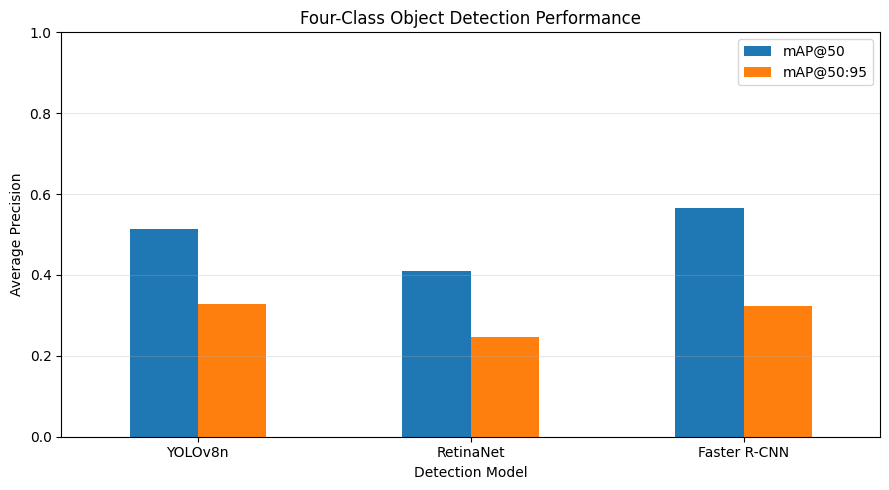

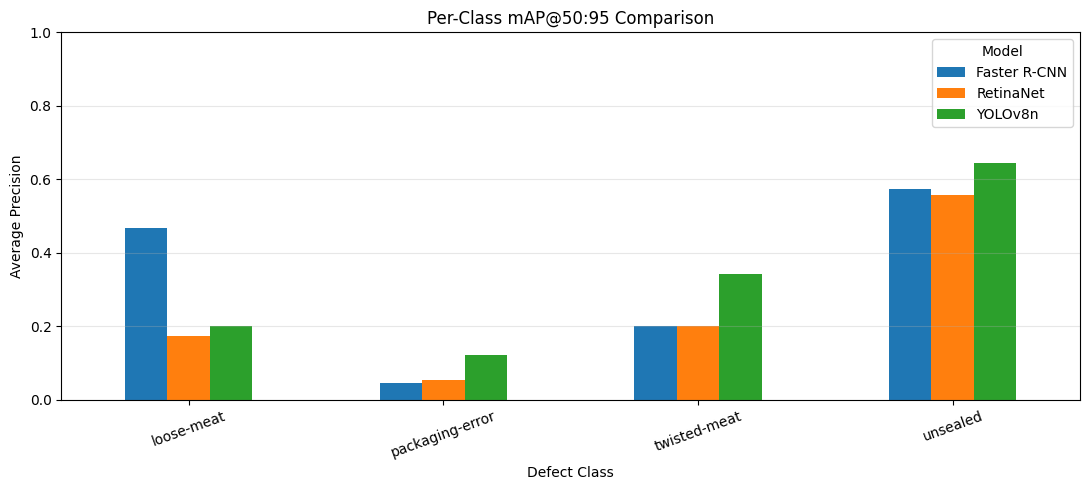

In [ ]:

# ----------------------------------------
# Overall mAP comparison
# ----------------------------------------
ax = overall_map_df.set_index("Model")[
    ["mAP50", "mAP50_95"]
].plot(
    kind="bar",
    figsize=(9, 5)
)

ax.set_title(
    "Four-Class Object Detection Performance"
)

ax.set_ylabel("Average Precision")
ax.set_xlabel("Detection Model")
ax.set_ylim(0, 1)

plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.legend(["mAP@50", "mAP@50:95"])
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "overall_map_comparison.png",
    dpi=180
)

plt.show()


# ----------------------------------------
# Per-class AP comparison
# ----------------------------------------
ap_pivot = per_class_ap_df.pivot(
    index="Class",
    columns="Model",
    values="AP50_95"
)

ap_pivot = ap_pivot.reindex(CLASS_NAMES)

ax = ap_pivot.plot(
    kind="bar",
    figsize=(11, 5)
)

ax.set_title(
    "Per-Class mAP@50:95 Comparison"
)

ax.set_ylabel("Average Precision")
ax.set_xlabel("Defect Class")
ax.set_ylim(0, 1)

plt.xticks(rotation=20)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "per_class_ap_comparison.png",
    dpi=180
)

plt.show()



## 7. Confidence Threshold Sensitivity Analysis

The models are compared at multiple confidence thresholds using
the same custom object-detection matching algorithm.

For each prediction, the algorithm identifies the best unmatched
ground-truth object using bounding-box IoU.

An IoU of at least 0.50 is required for a valid match.

The matching results are recorded in a confusion matrix with
four defect classes and one background category.

The following metrics are calculated:

- Precision
- Recall
- Micro-F1
- Macro-F1
- Macro-recall

Micro-F1 evaluates overall detection performance, while macro-F1
gives equal weight to the four defect classes.

Thresholds are selected using validation results only.


In [ ]:

BACKGROUND = NUM_CLASSES

MATRIX_LABELS = (
    CLASS_NAMES + ["background"]
)


def make_confusion_matrix(
    predictions,
    targets,
    threshold,
    match_iou=0.50
):
    """
    Construct an object-detection confusion matrix.

    Rows: predicted class
    Columns: true class

    Predictions are processed in descending confidence
    order and matched to the best remaining GT box.

    Unmatched predictions -> background column
    Unmatched GT objects -> background row

    Wrong-class matches appear off-diagonal.
    """

    cm = np.zeros(
        (NUM_CLASSES + 1, NUM_CLASSES + 1),
        dtype=np.int64
    )

    for prediction, target in zip(
        predictions, targets
    ):

        keep = (
            prediction["scores"] >= threshold
        )

        pred_boxes = prediction["boxes"][keep]
        pred_scores = prediction["scores"][keep]
        pred_labels = prediction["labels"][keep]

        gt_boxes = target["boxes"]
        gt_labels = target["labels"]

        # Highest-confidence predictions first
        order = torch.argsort(
            pred_scores,
            descending=True
        )

        pred_boxes = pred_boxes[order]
        pred_labels = pred_labels[order]

        matched_gt = set()

        for pred_box, pred_label in zip(
            pred_boxes, pred_labels
        ):

            pred_class = int(pred_label)

            if len(gt_boxes) == 0:
                cm[pred_class, BACKGROUND] += 1
                continue

            ious = box_iou(
                pred_box.unsqueeze(0),
                gt_boxes
            )[0]

            # A GT box can only be matched once
            for idx in matched_gt:
                ious[idx] = -1.0

            best_iou, best_idx = ious.max(0)
            best_idx = int(best_idx)

            if float(best_iou) >= match_iou:

                true_class = int(
                    gt_labels[best_idx]
                )

                cm[pred_class, true_class] += 1

                matched_gt.add(best_idx)

            else:
                cm[pred_class, BACKGROUND] += 1

        # Count missed ground-truth defects
        for idx, label in enumerate(gt_labels):
            if idx not in matched_gt:
                cm[BACKGROUND, int(label)] += 1

    return cm


def calculate_metrics(cm):
    """
    Calculate detection-level metrics from the matrix.

    Wrong-class matches count as:
      FP for the predicted class
      FN for the true class
    """

    n = NUM_CLASSES

    tp = int(np.trace(cm[:n, :n]))

    fp = int(
        cm[:n, :].sum() - tp
    )

    fn = int(
        cm[:, :n].sum() - tp
    )

    precision = (
        tp / (tp + fp)
        if tp + fp else 0.0
    )

    recall = (
        tp / (tp + fn)
        if tp + fn else 0.0
    )

    micro_f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall else 0.0
    )

    class_f1 = []
    class_recall = []

    for i in range(n):

        ctp = int(cm[i, i])
        cfp = int(cm[i, :].sum() - ctp)
        cfn = int(cm[:, i].sum() - ctp)

        cp = (
            ctp / (ctp + cfp)
            if ctp + cfp else 0.0
        )

        cr = (
            ctp / (ctp + cfn)
            if ctp + cfn else 0.0
        )

        cf1 = (
            2 * cp * cr / (cp + cr)
            if cp + cr else 0.0
        )

        class_f1.append(cf1)
        class_recall.append(cr)

    return {
        "TP": tp,
        "FP": fp,
        "FN": fn,
        "Precision": precision,
        "Recall": recall,
        "Micro_F1": micro_f1,
        "Macro_F1": float(np.mean(class_f1)),
        "Macro_Recall": float(np.mean(class_recall))
    }


In [ ]:

threshold_rows = []

# Use same threshold values for all three
for model_name, predictions in validation_predictions.items():

    print("Evaluating thresholds:", model_name)

    for threshold in FINE_THRESHOLDS:

        cm = make_confusion_matrix(
            predictions,
            valid_targets,
            threshold=float(threshold),
            match_iou=MATCH_IOU
        )

        metrics = calculate_metrics(cm)

        threshold_rows.append({
            "Model": model_name,
            "Threshold": float(threshold),
            **metrics
        })


threshold_df = pd.DataFrame(
    threshold_rows
)

print("\nCONFIDENCE THRESHOLD COMPARISON")

display(
    threshold_df[
        [
            "Model",
            "Threshold",
            "Precision",
            "Recall",
            "Micro_F1",
            "Macro_F1",
            "Macro_Recall"
        ]
    ].round(4)
)

threshold_df.to_csv(
    OUTPUT_DIR / "threshold_comparison.csv",
    index=False
)


Evaluating thresholds: YOLOv8n
Evaluating thresholds: RetinaNet
Evaluating thresholds: Faster R-CNN

CONFIDENCE THRESHOLD COMPARISON


,Model,Threshold,Precision,Recall,Micro_F1,Macro_F1,Macro_Recall
0,YOLOv8n,0.100,0.5266,0.8182,0.6408,0.5354,0.6359
1,YOLOv8n,0.125,0.5491,0.7851,0.6463,0.5455,0.6107
2,YOLOv8n,0.150,0.6090,0.7851,0.6859,0.6015,0.6107
3,YOLOv8n,0.175,0.6463,0.7851,0.7090,0.6116,0.6107
4,YOLOv8n,0.200,0.6667,0.7769,0.7176,0.6161,0.6077
5,YOLOv8n,0.225,0.6947,0.7521,0.7222,0.4291,0.4336
6,YOLOv8n,0.250,0.7479,0.7355,0.7417,0.4332,0.4189
7,YOLOv8n,0.275,0.7611,0.7107,0.7350,0.4196,0.3969
8,YOLOv8n,0.300,0.7818,0.7107,0.7446,0.4243,0.3969
9,YOLOv8n,0.325,0.8095,0.7025,0.7522,0.4239,0.3895


In [ ]:

selected_rows = []

for model_name in MODEL_NAMES:

    model_df = threshold_df[
        threshold_df["Model"] == model_name
    ]

    # Select highest micro-F1
    best_micro = model_df.loc[
        model_df["Micro_F1"].idxmax()
    ]

    # Select highest macro-F1
    best_macro = model_df.loc[
        model_df["Macro_F1"].idxmax()
    ]

    selected_rows.append({
        "Model": model_name,

        "Micro_Threshold": float(
            best_micro["Threshold"]
        ),

        "Best_Micro_F1": float(
            best_micro["Micro_F1"]
        ),

        "Macro_Threshold": float(
            best_macro["Threshold"]
        ),

        "Best_Macro_F1": float(
            best_macro["Macro_F1"]
        ),

        "Macro_Point_Precision": float(
            best_macro["Precision"]
        ),

        "Macro_Point_Recall": float(
            best_macro["Recall"]
        ),

        "Macro_Point_Micro_F1": float(
            best_macro["Micro_F1"]
        )
    })


selected_df = pd.DataFrame(selected_rows)

print("VALIDATION-SELECTED OPERATING POINTS")
display(selected_df.round(4))

selected_df.to_csv(
    OUTPUT_DIR / "selected_thresholds.csv",
    index=False
)


VALIDATION-SELECTED OPERATING POINTS


,Model,Micro_Threshold,Best_Micro_F1,Macro_Threshold,Best_Macro_F1,Macro_Point_Precision,Macro_Point_Recall,Macro_Point_Micro_F1
0,YOLOv8n,0.45,0.7664,0.2,0.6161,0.6667,0.7769,0.7176
1,RetinaNet,0.50,0.6979,0.2,0.3142,0.4314,0.7273,0.5415
2,Faster R-CNN,0.50,0.6809,0.5,0.5962,0.7018,0.6612,0.6809


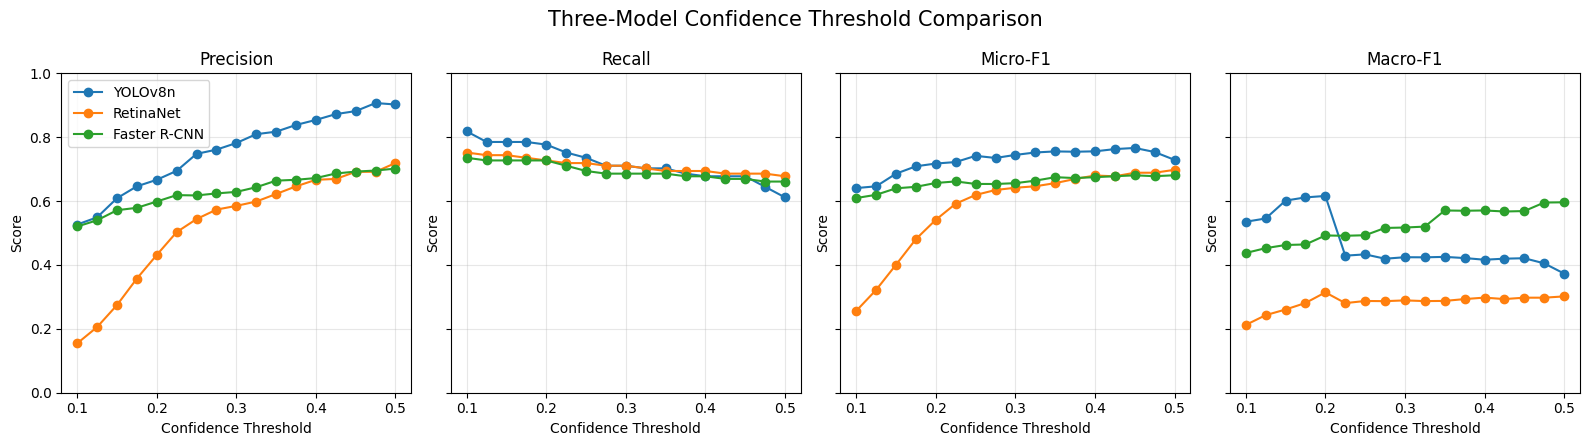

In [ ]:

metrics_to_plot = [
    "Precision",
    "Recall",
    "Micro_F1",
    "Macro_F1"
]

fig, axes = plt.subplots(1, 4, figsize=(16, 4.5), sharex=True, sharey=True)

axes = axes.flatten()

for ax, metric in zip(axes, metrics_to_plot):

    for model_name in MODEL_NAMES:

        model_df = threshold_df[
            threshold_df["Model"] == model_name
        ]

        ax.plot(
            model_df["Threshold"],
            model_df[metric],
            marker="o",
            label=model_name
        )

    ax.set_title(metric.replace("_", "-"))
    ax.set_ylabel("Score")
    ax.set_ylim(0, 1)
    ax.grid(True, alpha=0.3)

for ax in axes:
    ax.set_xlabel("Confidence Threshold")

axes[0].legend()

plt.suptitle(
    "Three-Model Confidence Threshold Comparison",
    fontsize=15
)

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "threshold_sensitivity_all_models.png",
    dpi=180,
    bbox_inches="tight"
)

plt.show()


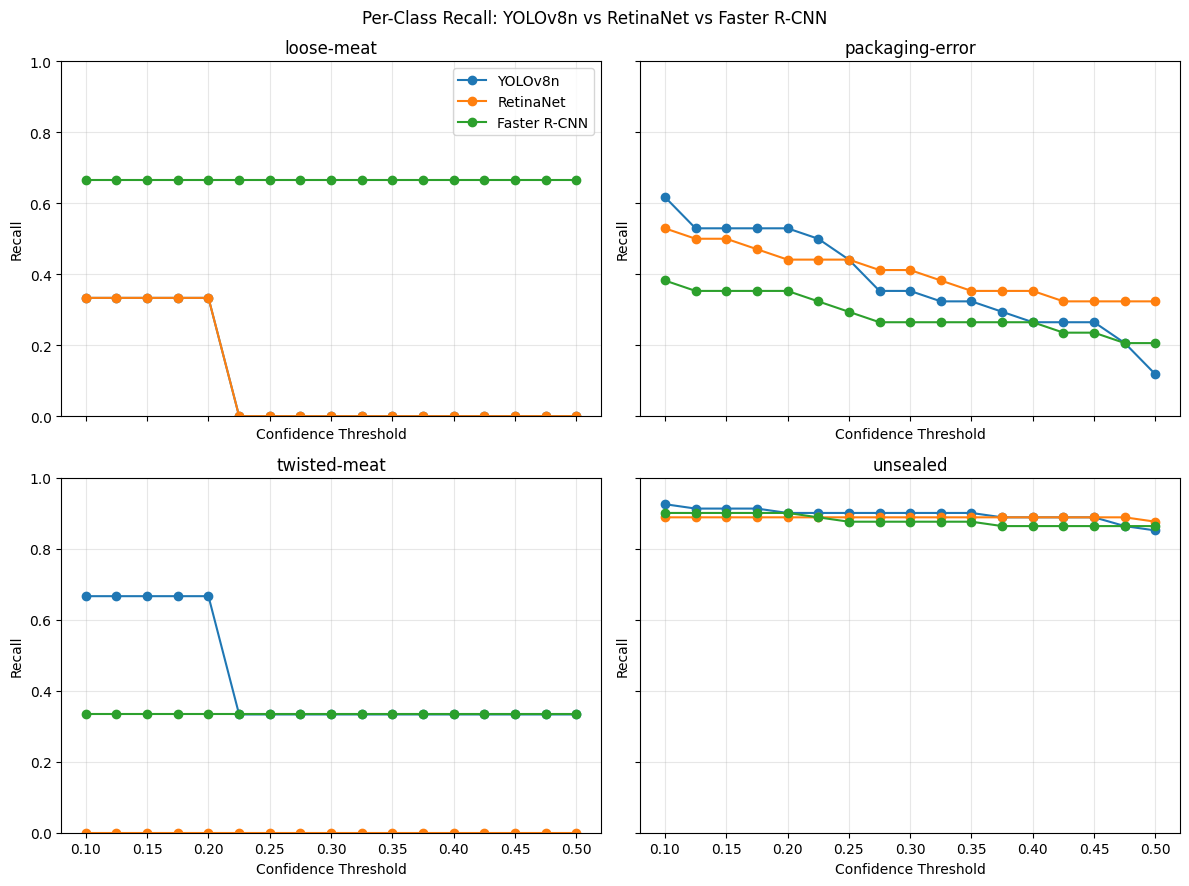

In [ ]:

per_class_rows = []

for model_name in MODEL_NAMES:

    model_preds = validation_predictions[
        model_name
    ]

    for threshold in FINE_THRESHOLDS:

        cm = make_confusion_matrix(
            model_preds,
            valid_targets,
            float(threshold)
        )

        for class_idx, class_name in enumerate(
            CLASS_NAMES
        ):

            tp = cm[class_idx, class_idx]

            total_gt = cm[:, class_idx].sum()

            recall = (
                tp / total_gt
                if total_gt > 0 else np.nan
            )

            per_class_rows.append({
                "Model": model_name,
                "Threshold": threshold,
                "Class": class_name,
                "Recall": recall
            })


per_class_recall_df = pd.DataFrame(
    per_class_rows
)

# Plot one graph for each defect class
fig, axes = plt.subplots(
    2, 2,
    figsize=(12, 9),
    sharex=True,
    sharey=True
)

for ax, class_name in zip(
    axes.flatten(),
    CLASS_NAMES
):

    class_data = per_class_recall_df[
        per_class_recall_df["Class"] == class_name
    ]

    for model_name in MODEL_NAMES:

        data = class_data[
            class_data["Model"] == model_name
        ]

        ax.plot(
            data["Threshold"],
            data["Recall"],
            marker="o",
            label=model_name
        )

    ax.set_title(class_name)
    ax.set_ylim(0, 1)
    ax.grid(True, alpha=0.3)

    ax.set_xlabel("Confidence Threshold")
    ax.set_ylabel("Recall")

axes[0, 0].legend()

plt.suptitle(
    "Per-Class Recall: YOLOv8n vs RetinaNet vs Faster R-CNN"
)

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "per_class_recall_comparison.png",
    dpi=180
)

plt.show()

per_class_recall_df.to_csv(
    OUTPUT_DIR / "per_class_recall.csv",
    index=False
)



## 8. Confusion Matrix Comparison

A confusion matrix is generated for each of the three models
using its validation-selected macro-F1 confidence threshold.

All matrices use the same IoU matching threshold of 0.50.

Raw confusion matrices show the numbers of correct detections,
misclassifications, false positives and false negatives.

Normalised matrices show the prediction distribution for each
ground-truth class.

The comparison focuses particularly on missed defects and
the ability of each model to detect minority classes.

Although model-specific confidence thresholds differ, they
are selected using the same validation procedure.


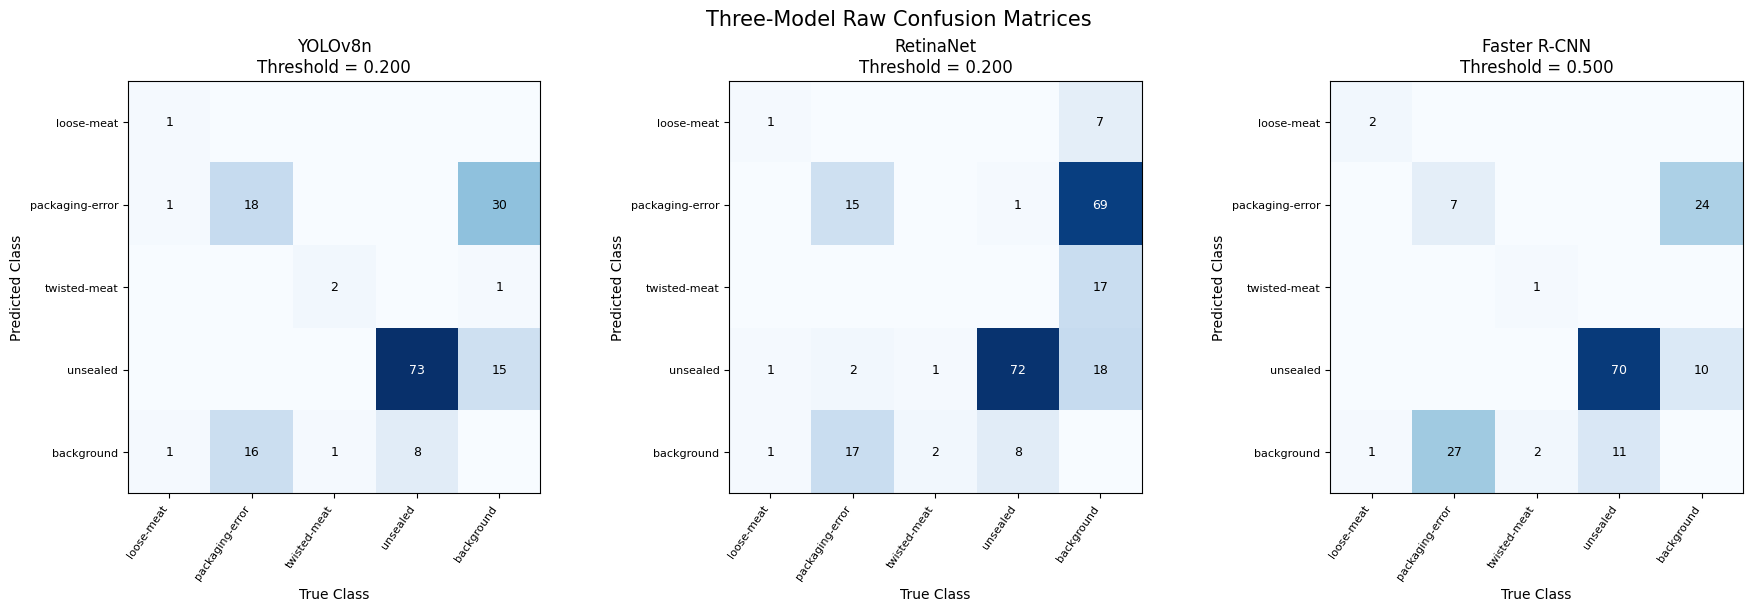

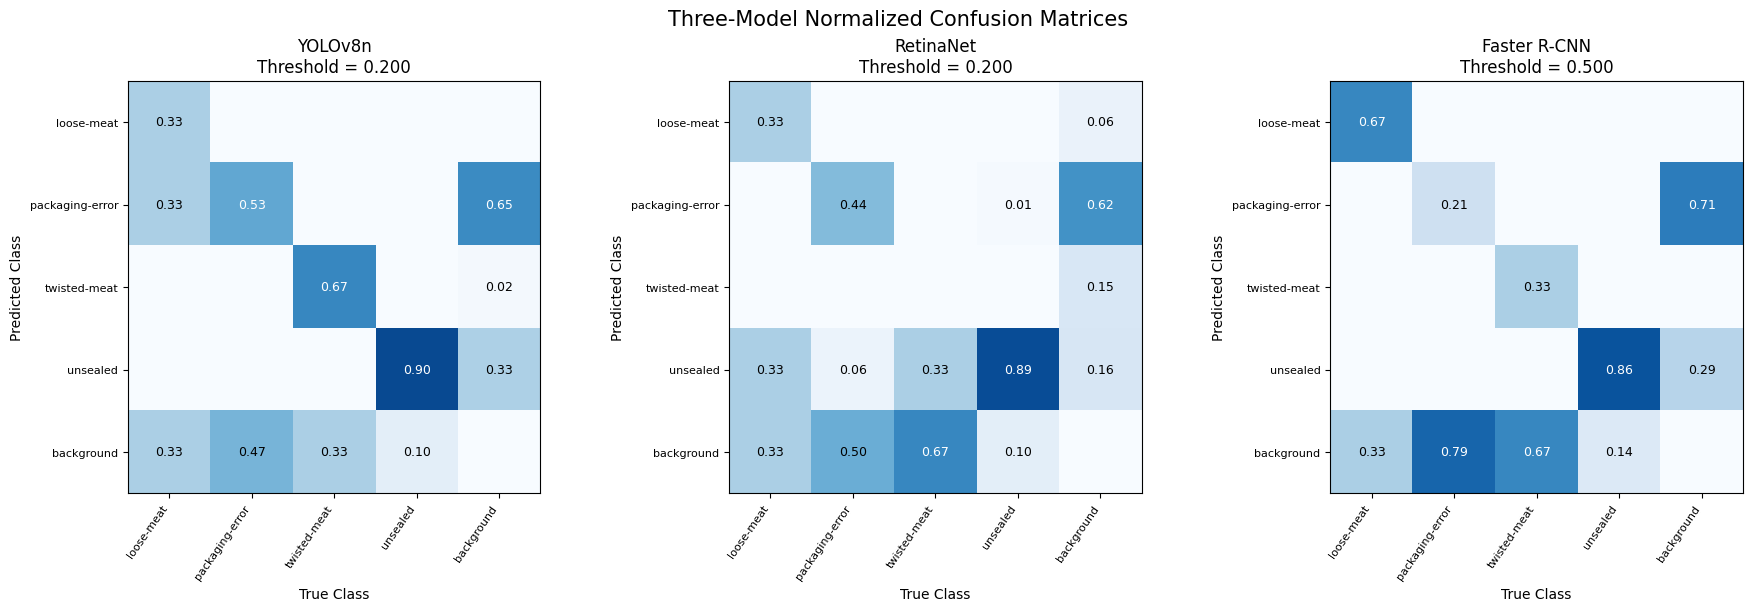

In [ ]:

def plot_model_matrices(normalized=False):

    fig, axes = plt.subplots(
        1, 3,
        figsize=(18, 6),
        constrained_layout=True
    )

    matrices = []
    thresholds = []

    for model_name in MODEL_NAMES:

        row = selected_df[
            selected_df["Model"] == model_name
        ].iloc[0]

        threshold = float(
            row["Macro_Threshold"]
        )

        cm = make_confusion_matrix(
            validation_predictions[model_name],
            valid_targets,
            threshold
        )

        matrices.append(cm)
        thresholds.append(threshold)

    # Shared scale across all model matrices
    vmax = (
        1.0 if normalized
        else max(cm.max() for cm in matrices)
    )

    for ax, model_name, threshold, cm in zip(
        axes,
        MODEL_NAMES,
        thresholds,
        matrices
    ):

        if normalized:

            totals = cm.sum(
                axis=0,
                keepdims=True
            )

            data = np.divide(
                cm.astype(float),
                totals,
                out=np.zeros_like(
                    cm, dtype=float
                ),
                where=totals != 0
            )

        else:
            data = cm

        ax.imshow(
            data,
            cmap="Blues",
            vmin=0,
            vmax=vmax
        )

        ax.set_title(
            f"{model_name}\nThreshold = {threshold:.3f}"
        )

        ax.set_xticks(range(NUM_CLASSES + 1))
        ax.set_yticks(range(NUM_CLASSES + 1))

        ax.set_xticklabels(
            MATRIX_LABELS,
            rotation=55,
            ha="right",
            fontsize=8
        )

        ax.set_yticklabels(
            MATRIX_LABELS,
            fontsize=8
        )

        ax.set_xlabel("True Class")
        ax.set_ylabel("Predicted Class")

        for i in range(NUM_CLASSES + 1):
            for j in range(NUM_CLASSES + 1):

                value = data[i, j]

                if value > 0:

                    label = (
                        f"{value:.2f}"
                        if normalized
                        else str(value)
                    )

                    ax.text(
                        j, i, label,
                        ha="center",
                        va="center",
                        fontsize=9,
                        color=(
                            "white"
                            if value > vmax / 2
                            else "black"
                        )
                    )

    kind = (
        "normalized" if normalized else "raw"
    )

    fig.suptitle(
        f"Three-Model {kind.title()} Confusion Matrices",
        fontsize=15
    )

    fig.savefig(
        OUTPUT_DIR /
        f"three_model_confusion_{kind}.png",
        dpi=180,
        bbox_inches="tight"
    )

    plt.show()


plot_model_matrices(normalized=False)
plot_model_matrices(normalized=True)


In [ ]:

error_rows = []

for model_name in MODEL_NAMES:

    threshold = float(
        selected_df.loc[
            selected_df["Model"] == model_name,
            "Macro_Threshold"
        ].iloc[0]
    )

    cm = make_confusion_matrix(
        validation_predictions[model_name],
        valid_targets,
        threshold
    )

    metrics = calculate_metrics(cm)

    # Missed detections that became background
    missed_background = int(
        cm[BACKGROUND, :NUM_CLASSES].sum()
    )

    # Predictions on background/unmatched regions
    unmatched_predictions = int(
        cm[:NUM_CLASSES, BACKGROUND].sum()
    )

    # Predictions assigned to the wrong defect class
    wrong_class = int(
        cm[:NUM_CLASSES, :NUM_CLASSES].sum()
        - np.trace(cm[:NUM_CLASSES, :NUM_CLASSES])
    )

    error_rows.append({
        "Model": model_name,
        "Threshold": threshold,
        "Correct_Detections": metrics["TP"],
        "Missed_to_Background": missed_background,
        "Unmatched_Predictions": unmatched_predictions,
        "Wrong_Class": wrong_class,
        "Precision": metrics["Precision"],
        "Recall": metrics["Recall"],
        "Macro_F1": metrics["Macro_F1"]
    })


error_df = pd.DataFrame(error_rows)

print("DETECTION ERROR COMPARISON")
display(error_df.round(4))

error_df.to_csv(
    OUTPUT_DIR / "detection_error_comparison.csv",
    index=False
)


DETECTION ERROR COMPARISON


,Model,Threshold,Correct_Detections,Missed_to_Background,Unmatched_Predictions,Wrong_Class,Precision,Recall,Macro_F1
0,YOLOv8n,0.2,94,26,46,1,0.6667,0.7769,0.6161
1,RetinaNet,0.2,88,28,111,5,0.4314,0.7273,0.3142
2,Faster R-CNN,0.5,80,41,34,0,0.7018,0.6612,0.5962



## 9. Computational Performance Evaluation

The computational requirements of the three models are compared
using the same Google Colab hardware.

The following metrics are measured:

1. Model parameter count
2. Model weight size
3. Median single-image inference time
4. Frames per second (FPS)
5. Peak GPU memory during inference
6. Training time recorded by the original notebooks

Each model is evaluated after GPU warm-up to reduce initialisation
overhead.

Inference timing uses the same validation image, batch size of one
and repeated forward passes.

Reported inference times include model preprocessing and internal
postprocessing, but exclude disk image loading.

The measurements represent single-image throughput and do not
necessarily represent maximum batch-processing performance.


In [ ]:

# ----------------------------------------
# Model parameter counts
# ----------------------------------------
model_objects = {
    "YOLOv8n": yolo_model.model,
    "RetinaNet": retinanet_model,
    "Faster R-CNN": faster_model
}


def count_parameters(model):
    return sum(
        p.numel() for p in model.parameters()
    )


def weight_size_mb(model):
    """
    Calculate raw state-dictionary tensor storage.

    This excludes optimiser state and checkpoint
    metadata, making it more suitable than
    comparing full training checkpoint sizes.
    """
    return sum(
        t.numel() * t.element_size()
        for t in model.state_dict().values()
    ) / (1024 ** 2)


# ----------------------------------------
# Benchmark settings
# ----------------------------------------
BENCHMARK_REPEATS = 50
WARMUP_REPEATS = 10

# Same validation image for all models
benchmark_path = valid_image_paths[0]

benchmark_tensor = load_image_tensor(
    benchmark_path
).to(device)


def synchronize_gpu():
    if device.type == "cuda":
        torch.cuda.synchronize()


@torch.no_grad()
def benchmark_model(name):
    """
    Benchmark batch-size-one inference.

    Includes model preprocessing and postprocessing.
    Excludes disk image loading.
    """

    # Prepare model-specific inference call
    if name == "YOLOv8n":

        # Use a preloaded image array
        image_np = (
            benchmark_tensor
            .permute(1, 2, 0)
            .mul(255)
            .byte()
            .cpu()
            .numpy()
        )

        def infer():
            return yolo_model.predict(
                source=image_np,
                imgsz=IMAGE_SIZE,
                conf=0.001,
                iou=0.70,
                max_det=300,
                device=0 if device.type == "cuda" else "cpu",
                verbose=False
            )

    elif name == "RetinaNet":

        def infer():
            return retinanet_model(
                [benchmark_tensor]
            )

    else:

        def infer():
            return faster_model(
                [benchmark_tensor]
            )

    # Warm-up iterations
    for _ in range(WARMUP_REPEATS):
        infer()

    synchronize_gpu()

    if device.type == "cuda":
        torch.cuda.reset_peak_memory_stats()

    timings = []

    for _ in range(BENCHMARK_REPEATS):

        synchronize_gpu()
        start = time.perf_counter()

        infer()

        synchronize_gpu()
        elapsed = time.perf_counter() - start

        timings.append(elapsed * 1000)

    median_ms = float(np.median(timings))
    fps = 1000.0 / median_ms

    peak_mb = (
        torch.cuda.max_memory_allocated()
        / (1024 ** 2)
        if device.type == "cuda"
        else np.nan
    )

    return median_ms, fps, peak_mb


# ----------------------------------------
# Run benchmarks
# ----------------------------------------
compute_rows = []

for name in MODEL_NAMES:

    print("Benchmarking:", name)

    gc.collect()

    if device.type == "cuda":
        torch.cuda.empty_cache()

    model = model_objects[name]

    median_ms, fps, peak_mb = benchmark_model(
        name
    )

    compute_rows.append({
        "Model": name,
        "Parameters_M": (
            count_parameters(model) / 1e6
        ),
        "Weight_Size_MB": weight_size_mb(model),
        "Inference_ms": median_ms,
        "FPS": fps,
        "Peak_GPU_MB": peak_mb
    })


compute_df = pd.DataFrame(compute_rows)

print("\nCOMPUTATIONAL PERFORMANCE")
display(compute_df.round(3))

compute_df.to_csv(
    OUTPUT_DIR / "computational_comparison.csv",
    index=False
)


Benchmarking: YOLOv8n
Benchmarking: RetinaNet
Benchmarking: Faster R-CNN

COMPUTATIONAL PERFORMANCE


,Model,Parameters_M,Weight_Size_MB,Inference_ms,FPS,Peak_GPU_MB
0,YOLOv8n,3.139,12.014,11.553,86.554,377.154
1,RetinaNet,36.415,139.115,63.036,15.864,425.432
2,Faster R-CNN,43.272,165.294,112.520,8.887,825.545



## 10. Detection Accuracy and Computational Cost Trade-off

The standardised mAP@50:95 results are compared against model
inference time to investigate the relationship between detection
quality and computational requirements.

An accuracy-speed scatter plot is generated, with inference time
on the horizontal axis and mAP@50:95 on the vertical axis.

A model may achieve higher detection performance but require
greater processing time, memory or storage.

The analysis considers whether any improvement in detection
performance is sufficient to justify its additional computational
cost for potential industrial inspection.


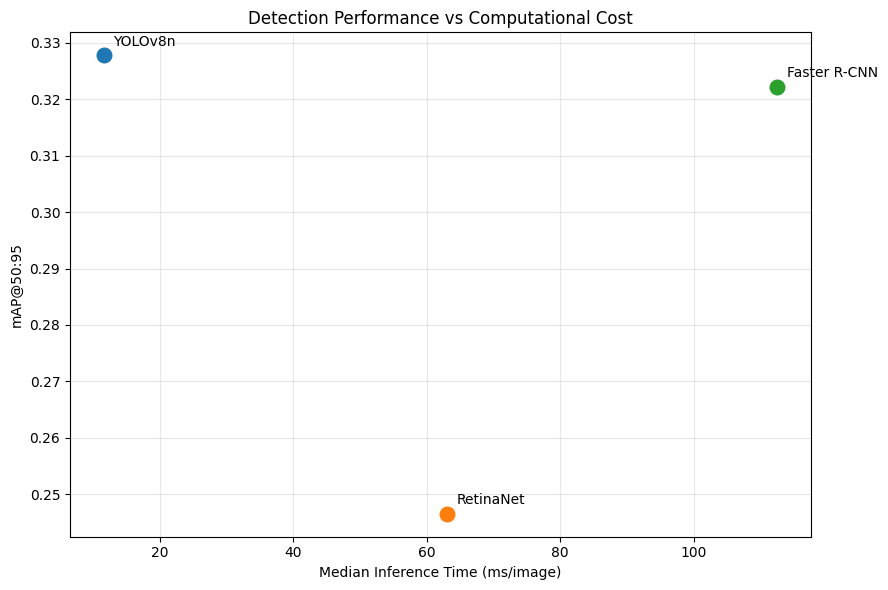

ACCURACY-SPEED COMPARISON


,Model,mAP50_95,Inference_ms,FPS,Parameters_M,Weight_Size_MB
0,YOLOv8n,0.3278,11.5535,86.5540,3.1387,12.0142
1,RetinaNet,0.2465,63.0356,15.8640,36.4149,139.1147
2,Faster R-CNN,0.3222,112.5199,8.8873,43.2715,165.2943


In [ ]:

tradeoff_df = overall_map_df.merge(
    compute_df,
    on="Model"
)

plt.figure(figsize=(9, 6))

for _, row in tradeoff_df.iterrows():

    plt.scatter(
        row["Inference_ms"],
        row["mAP50_95"],
        s=110
    )

    plt.annotate(
        row["Model"],
        (
            row["Inference_ms"],
            row["mAP50_95"]
        ),
        xytext=(7, 7),
        textcoords="offset points"
    )

plt.xlabel("Median Inference Time (ms/image)")
plt.ylabel("mAP@50:95")

plt.title(
    "Detection Performance vs Computational Cost"
)

plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "accuracy_speed_tradeoff.png",
    dpi=180
)

plt.show()


print("ACCURACY-SPEED COMPARISON")

display(
    tradeoff_df[
        [
            "Model",
            "mAP50_95",
            "Inference_ms",
            "FPS",
            "Parameters_M",
            "Weight_Size_MB"
        ]
    ].round(4)
)


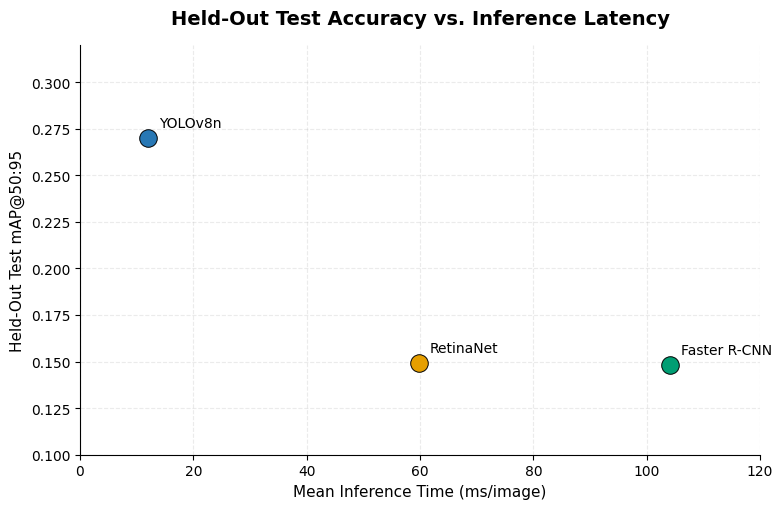

       Model  Test_mAP50_95  Inference_ms     FPS  Parameters_M  Weight_Size_MB
     YOLOv8n         0.2698       11.9407 83.7473        3.1387         12.0142
   RetinaNet         0.1494       59.7758 16.7292       36.4149        139.1147
Faster R-CNN         0.1482      104.0627  9.6096       43.2715        165.2943


In [ ]:

import matplotlib.pyplot as plt
import pandas as pd
from pathlib import Path

# ============================================================
# Figure 5.2.0 — Test Accuracy vs Inference Latency
#
# TODO (Notebook 07 housekeeping):
# Replace hardcoded TEST mAP50:95 values with values loaded
# automatically from the saved held-out test evaluation results.
# Ensure benchmark metrics and test metrics use the same
# final selected model checkpoints.
# ============================================================

results = pd.DataFrame({
    "Model": ["YOLOv8n", "RetinaNet", "Faster R-CNN"],
    "Test_mAP50_95": [0.2698, 0.1494, 0.1482],
    "Inference_ms": [11.9407, 59.7758, 104.0627],
    "FPS": [83.7473, 16.7292, 9.6096],
    "Parameters_M": [3.1387, 36.4149, 43.2715],
    "Weight_Size_MB": [12.0142, 139.1147, 165.2943],
})

fig, ax = plt.subplots(figsize=(8, 5.2))

colors = ["#2878B5", "#E69F00", "#009E73"]

for i, row in results.iterrows():
    ax.scatter(
        row["Inference_ms"],
        row["Test_mAP50_95"],
        s=160,
        color=colors[i],
        edgecolor="black",
        linewidth=0.7,
        zorder=3
    )

    ax.annotate(
        row["Model"],
        (row["Inference_ms"], row["Test_mAP50_95"]),
        xytext=(8, 8),
        textcoords="offset points",
        fontsize=10
    )

ax.set_xlabel("Mean Inference Time (ms/image)", fontsize=11)
ax.set_ylabel("Held-Out Test mAP@50:95", fontsize=11)

ax.set_xlim(0, 120)
ax.set_ylim(0.10, 0.32)

ax.grid(alpha=0.25, linestyle="--")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.set_title(
    "Held-Out Test Accuracy vs. Inference Latency",
    fontsize=14,
    fontweight="bold",
    pad=15
)
plt.tight_layout()

output_dir = Path("/content/report_figures")
output_dir.mkdir(parents=True, exist_ok=True)

plt.savefig(
    output_dir / "figure_5_2_0_accuracy_vs_latency.png",
    dpi=300,
    bbox_inches="tight"
)
plt.savefig(
    output_dir / "figure_5_2_0_accuracy_vs_latency.pdf",
    bbox_inches="tight"
)

plt.show()

print(results.round(4).to_string(index=False))



## 11. Consolidated Validation Results

The results from all three models are combined into a single
comparison table.

The analysis considers three main dimensions:

1. Detection quality — mAP@50:95 and per-class AP
2. Defect detection reliability — recall, macro-F1 and errors
3. Computational efficiency — inference speed, parameters and memory

The model with the highest mAP is not automatically considered
the most suitable for industrial deployment.

The final assessment considers the trade-off between localisation
performance, missed defects and computational requirements.

All conclusions at this stage are based on validation data.


In [ ]:

# Combine performance, threshold and compute results
final_validation_df = (
    overall_map_df
    .merge(selected_df, on="Model")
    .merge(compute_df, on="Model")
    .merge(
        error_df[
            [
                "Model",
                "Missed_to_Background",
                "Unmatched_Predictions",
                "Wrong_Class"
            ]
        ],
        on="Model"
    )
)

columns = [
    "Model",
    "mAP50",
    "mAP50_95",
    "Macro_Threshold",
    "Best_Macro_F1",
    "Macro_Point_Recall",
    "Missed_to_Background",
    "Parameters_M",
    "Inference_ms",
    "FPS",
    "Weight_Size_MB",
    "Peak_GPU_MB"
]

print("FINAL VALIDATION COMPARISON")

display(
    final_validation_df[columns].round(4)
)

final_validation_df.to_csv(
    OUTPUT_DIR / "final_validation_comparison.csv",
    index=False
)

# Identify highest validation mAP
best_map_row = final_validation_df.loc[
    final_validation_df["mAP50_95"].idxmax()
]

# Identify fastest measured model
fastest_row = final_validation_df.loc[
    final_validation_df["Inference_ms"].idxmin()
]

# Identify highest macro-F1
best_macro_row = final_validation_df.loc[
    final_validation_df["Best_Macro_F1"].idxmax()
]

print("\nVALIDATION FINDINGS")

print(
    "Highest mAP@50:95:",
    best_map_row["Model"]
)

print(
    "Fastest inference:",
    fastest_row["Model"]
)

print(
    "Highest macro-F1:",
    best_macro_row["Model"]
)


FINAL VALIDATION COMPARISON


,Model,mAP50,mAP50_95,Macro_Threshold,Best_Macro_F1,Macro_Point_Recall,Missed_to_Background,Parameters_M,Inference_ms,FPS,Weight_Size_MB,Peak_GPU_MB
0,YOLOv8n,0.5147,0.3278,0.2,0.6161,0.7769,26,3.1387,11.5535,86.5540,12.0142,377.1538
1,RetinaNet,0.4098,0.2465,0.2,0.3142,0.7273,28,36.4149,63.0356,15.8640,139.1147,425.4316
2,Faster R-CNN,0.5662,0.3222,0.5,0.5962,0.6612,41,43.2715,112.5199,8.8873,165.2943,825.5449



VALIDATION FINDINGS
Highest mAP@50:95: YOLOv8n
Fastest inference: YOLOv8n
Highest macro-F1: YOLOv8n



## 12. Held-Out Test Evaluation

The final evaluation uses the previously unseen four-class
test dataset.

Before testing, the following decisions are fixed:

- Best checkpoint for each model
- Confidence-threshold selection procedure
- Bounding-box matching criterion
- Model-specific preprocessing and postprocessing
- Evaluation metrics

The test set is not used to select confidence thresholds,
adjust hyperparameters or choose model checkpoints.

All three frozen models are evaluated using the same test
annotations and standardised mAP implementation.

The resulting test performance provides the final evidence
for comparing their generalisation to unseen images.


In [ ]:

# Safety gate: deliberately disabled by default
RUN_FINAL_TEST = True

if not RUN_FINAL_TEST:

    print(
        "Final test evaluation is disabled.\n"
        "Complete validation analysis and freeze "
        "model selection before setting "
        "RUN_FINAL_TEST = True."
    )

else:

    # Load held-out test annotations
    test_image_paths, test_targets = load_dataset(
        "test"
    )

    print("Test images:", len(test_image_paths))

    # Generate test predictions once
    test_predictions = {
        "YOLOv8n": predict_yolo(
            test_image_paths
        ),
        "RetinaNet": predict_torchvision(
            retinanet_model,
            test_image_paths
        ),
        "Faster R-CNN": predict_torchvision(
            faster_model,
            test_image_paths
        )
    }

    test_rows = []
    test_class_rows = []

    for name, predictions in test_predictions.items():

        # Standardised mAP
        result = evaluate_map(
            predictions,
            test_targets
        )

        # Use frozen validation-selected threshold
        threshold = float(
            selected_df.loc[
                selected_df["Model"] == name,
                "Macro_Threshold"
            ].iloc[0]
        )

        cm = make_confusion_matrix(
            predictions,
            test_targets,
            threshold
        )

        metrics = calculate_metrics(cm)

        test_rows.append({
            "Model": name,
            "mAP50": float(result["map_50"]),
            "mAP50_95": float(result["map"]),
            "Threshold": threshold,
            **metrics
        })

        # Per-class AP
        ap_by_class = {
            int(c): float(ap)
            for c, ap in zip(
                result["classes"],
                result["map_per_class"]
            )
        }

        for class_id, class_name in enumerate(
            CLASS_NAMES
        ):

            test_class_rows.append({
                "Model": name,
                "Class": class_name,
                "AP50_95": ap_by_class.get(
                    class_id, np.nan
                )
            })

    test_results_df = pd.DataFrame(test_rows)
    test_class_df = pd.DataFrame(test_class_rows)

    print("\nFINAL TEST RESULTS")
    display(test_results_df.round(4))

    print("\nTEST PER-CLASS AP")
    display(
        test_class_df.pivot(
            index="Class",
            columns="Model",
            values="AP50_95"
        ).round(4)
    )

    # Save final test results
    test_results_df.to_csv(
        OUTPUT_DIR / "final_test_results.csv",
        index=False
    )

    test_class_df.to_csv(
        OUTPUT_DIR / "final_test_per_class_ap.csv",
        index=False
    )

    print("\nFinal test evaluation completed.")


Test images: 80

FINAL TEST RESULTS


,Model,mAP50,mAP50_95,Threshold,TP,FP,FN,Precision,Recall,Micro_F1,Macro_F1,Macro_Recall
0,YOLOv8n,0.5252,0.2698,0.2,54,24,25,0.6923,0.6835,0.6879,0.3321,0.3447
1,RetinaNet,0.2797,0.1494,0.2,52,70,27,0.4262,0.6582,0.5174,0.2704,0.3287
2,Faster R-CNN,0.2716,0.1482,0.5,48,18,31,0.7273,0.6076,0.6621,0.2890,0.2795



TEST PER-CLASS AP


Model,Faster R-CNN,RetinaNet,YOLOv8n
Class,,,
loose-meat,0.0004,0.0000,0.2608
packaging-error,0.0619,0.0711,0.1481
twisted-meat,0.0027,0.0000,0.0921
unsealed,0.5280,0.5266,0.5782



Final test evaluation completed.


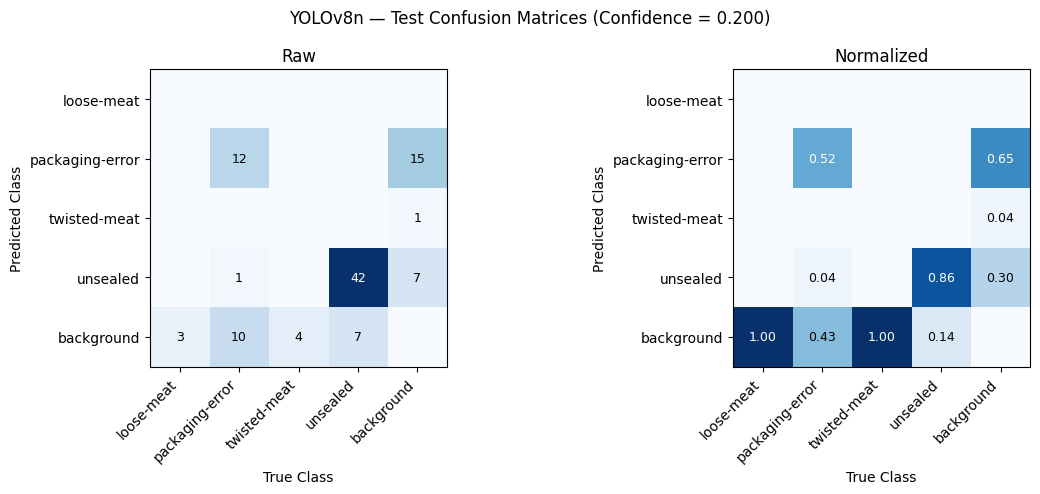

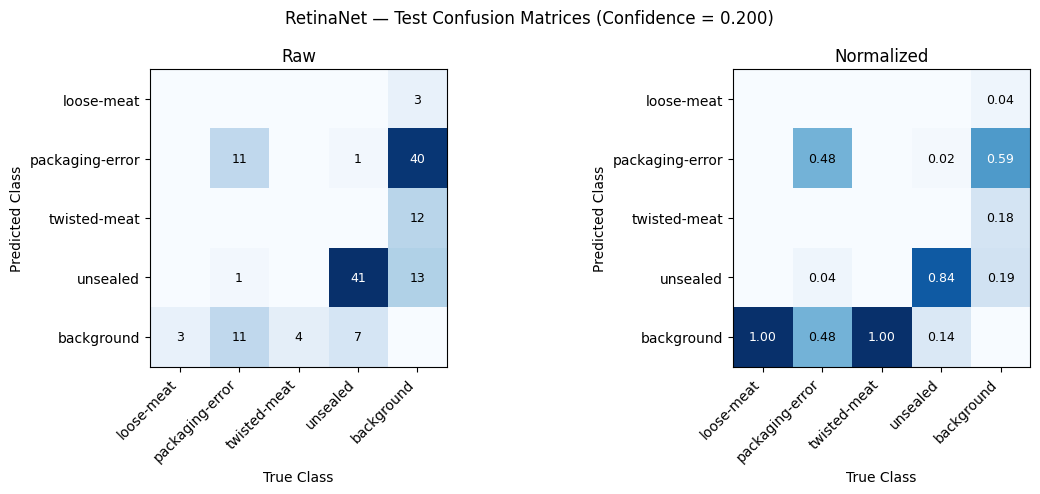

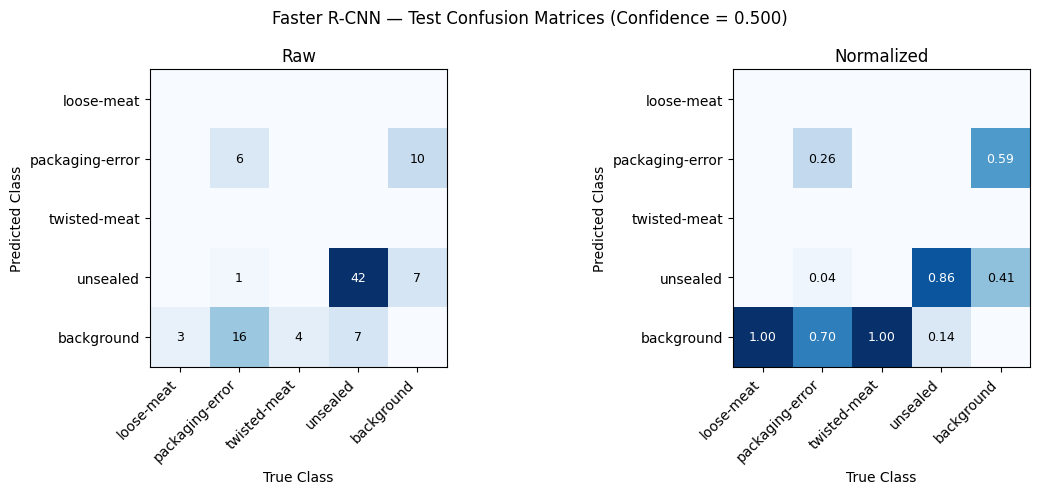

In [ ]:

# Only run after completing final test evaluation
assert RUN_FINAL_TEST is True
assert "test_predictions" in globals()

# Display test confusion matrices using
# validation-selected confidence thresholds.
for model_name in MODEL_NAMES:

    threshold = float(
        selected_df.loc[
            selected_df["Model"] == model_name,
            "Macro_Threshold"
        ].iloc[0]
    )

    cm = make_confusion_matrix(
        test_predictions[model_name],
        test_targets,
        threshold=threshold,
        match_iou=MATCH_IOU
    )

    # Normalise each true-class column
    totals = cm.sum(axis=0, keepdims=True)

    cm_normalized = np.divide(
        cm.astype(float),
        totals,
        out=np.zeros_like(cm, dtype=float),
        where=totals != 0
    )

    fig, axes = plt.subplots(
        1, 2, figsize=(12, 5)
    )

    for ax, data, title in zip(
        axes,
        [cm, cm_normalized],
        ["Raw", "Normalized"]
    ):

        vmax = max(1, cm.max()) if title == "Raw" else 1

        ax.imshow(
            data,
            cmap="Blues",
            vmin=0,
            vmax=vmax
        )

        ax.set_xticks(range(NUM_CLASSES + 1))
        ax.set_yticks(range(NUM_CLASSES + 1))

        ax.set_xticklabels(
            MATRIX_LABELS,
            rotation=45,
            ha="right"
        )
        ax.set_yticklabels(MATRIX_LABELS)

        ax.set_xlabel("True Class")
        ax.set_ylabel("Predicted Class")
        ax.set_title(title)

        for i in range(NUM_CLASSES + 1):
            for j in range(NUM_CLASSES + 1):
                value = data[i, j]

                if value > 0:
                    label = (
                        str(int(value))
                        if title == "Raw"
                        else f"{value:.2f}"
                    )
                    ax.text(
                        j, i, label,
                        ha="center", va="center",
                        color="white" if value > vmax / 2
                        else "black",
                        fontsize=9
                    )

    plt.suptitle(
        f"{model_name} — Test Confusion Matrices "
        f"(Confidence = {threshold:.3f})"
    )

    plt.tight_layout()
    plt.savefig(
        OUTPUT_DIR /
        f"{model_name.replace(' ', '_')}_test_cm.png",
        dpi=180,
        bbox_inches="tight"
    )
    plt.show()


VALIDATION VS TEST PERFORMANCE


,Model,mAP50_Valid,mAP50_95_Valid,mAP50_Test,mAP50_95_Test,mAP50_95_Change
0,YOLOv8n,0.5147,0.3278,0.5252,0.2698,-0.0580
1,RetinaNet,0.4098,0.2465,0.2797,0.1494,-0.0971
2,Faster R-CNN,0.5662,0.3222,0.2716,0.1482,-0.1740


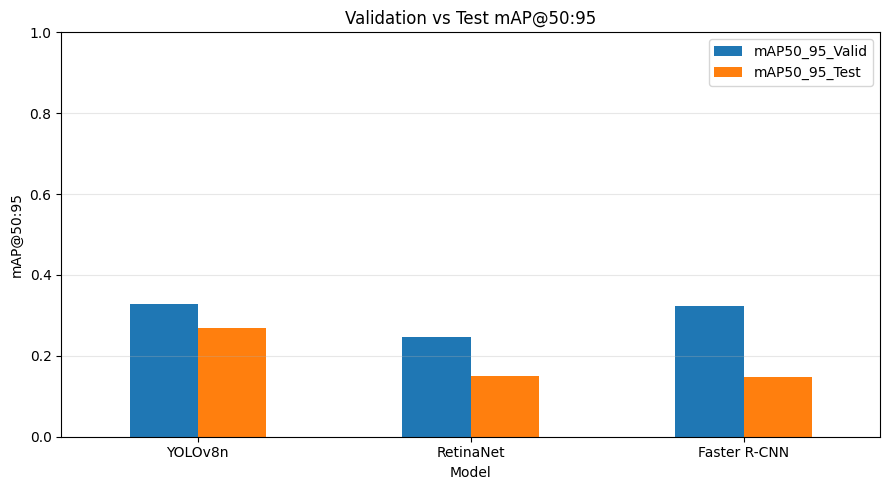

In [ ]:

# Compare standardised validation mAP with test mAP
comparison = overall_map_df.merge(
    test_results_df[
        ["Model", "mAP50", "mAP50_95"]
    ],
    on="Model",
    suffixes=("_Valid", "_Test")
)

comparison["mAP50_95_Change"] = (
    comparison["mAP50_95_Test"]
    - comparison["mAP50_95_Valid"]
)

print("VALIDATION VS TEST PERFORMANCE")
display(comparison.round(4))

comparison.to_csv(
    OUTPUT_DIR / "validation_vs_test.csv",
    index=False
)

# Visualise generalisation
ax = comparison.set_index("Model")[
    ["mAP50_95_Valid", "mAP50_95_Test"]
].plot(kind="bar", figsize=(9, 5))

ax.set_title("Validation vs Test mAP@50:95")
ax.set_ylabel("mAP@50:95")
ax.set_ylim(0, 1)

plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


In [ ]:

import numpy as np
import pandas as pd

# ---------------------------------------
# 1. Compare ground-truth class counts
# ---------------------------------------
def count_ground_truths(targets):
    counts = np.zeros(NUM_CLASSES, dtype=int)

    for target in targets:
        for label in target["labels"]:
            counts[int(label)] += 1

    return counts


valid_counts = count_ground_truths(valid_targets)
test_counts = count_ground_truths(test_targets)

# ---------------------------------------
# 2. Count Faster R-CNN predictions
# ---------------------------------------
def count_predictions(predictions, threshold):
    counts = np.zeros(NUM_CLASSES, dtype=int)

    for pred in predictions:
        keep = pred["scores"] >= threshold

        for label in pred["labels"][keep]:
            counts[int(label)] += 1

    return counts


# Frozen validation-selected operating threshold
threshold = float(
    selected_df.loc[
        selected_df["Model"] == "Faster R-CNN",
        "Macro_Threshold"
    ].iloc[0]
)

valid_pred_counts = count_predictions(
    validation_predictions["Faster R-CNN"],
    threshold
)

test_pred_counts = count_predictions(
    test_predictions["Faster R-CNN"],
    threshold
)

# ---------------------------------------
# 3. Compare correct detections
# ---------------------------------------
valid_cm = make_confusion_matrix(
    validation_predictions["Faster R-CNN"],
    valid_targets,
    threshold
)

test_cm = make_confusion_matrix(
    test_predictions["Faster R-CNN"],
    test_targets,
    threshold
)

# ---------------------------------------
# 4. Summary table
# ---------------------------------------
diagnostic_df = pd.DataFrame({
    "Class": CLASS_NAMES,
    "Validation_GT": valid_counts,
    "Test_GT": test_counts,
    "Validation_Predictions": valid_pred_counts,
    "Test_Predictions": test_pred_counts,
    "Validation_TP": np.diag(valid_cm)[:NUM_CLASSES],
    "Test_TP": np.diag(test_cm)[:NUM_CLASSES]
})

diagnostic_df["Validation_Recall"] = (
    diagnostic_df["Validation_TP"]
    / diagnostic_df["Validation_GT"].replace(0, np.nan)
)

diagnostic_df["Test_Recall"] = (
    diagnostic_df["Test_TP"]
    / diagnostic_df["Test_GT"].replace(0, np.nan)
)

print("FASTER R-CNN GENERALISATION DIAGNOSTICS")
print("Frozen confidence threshold:", threshold)

display(diagnostic_df.round(4))


FASTER R-CNN GENERALISATION DIAGNOSTICS
Frozen confidence threshold: 0.5


,Class,Validation_GT,Test_GT,Validation_Predictions,Test_Predictions,Validation_TP,Test_TP,Validation_Recall,Test_Recall
0,loose-meat,3,3,2,0,2,0,0.6667,0.0000
1,packaging-error,34,23,31,16,7,6,0.2059,0.2609
2,twisted-meat,3,4,1,0,1,0,0.3333,0.0000
3,unsealed,81,49,80,50,70,42,0.8642,0.8571


In [ ]:

import pandas as pd
import numpy as np

# Diagnostic only: do not change frozen threshold
model_preds = test_predictions["Faster R-CNN"]

rows = []

for class_id, class_name in enumerate(CLASS_NAMES):

    scores = []

    for prediction in model_preds:

        keep = (
            prediction["labels"] == class_id
        )

        scores.extend(
            prediction["scores"][keep].tolist()
        )

    rows.append({
        "Class": class_name,
        "Predictions_Returned": len(scores),
        "Maximum_Confidence": (
            max(scores) if scores else np.nan
        ),
        "Mean_Confidence": (
            np.mean(scores) if scores else np.nan
        ),
        "Predictions_Above_0.50": sum(
            score >= 0.50 for score in scores
        )
    })

confidence_df = pd.DataFrame(rows)

print("FASTER R-CNN TEST PREDICTION CONFIDENCE")
display(confidence_df.round(4))


FASTER R-CNN TEST PREDICTION CONFIDENCE


,Class,Predictions_Returned,Maximum_Confidence,Mean_Confidence,Predictions_Above_0.50
0,loose-meat,212,0.1228,0.0082,0
1,packaging-error,292,0.9717,0.0660,16
2,twisted-meat,208,0.1958,0.0093,0
3,unsealed,192,0.9962,0.2777,50


In [ ]:

import numpy as np
import pandas as pd
from torchvision.ops import box_iou

rows = []

predictions = test_predictions["Faster R-CNN"]

for class_id, class_name in enumerate(CLASS_NAMES):

    best_ious = []
    best_scores = []

    for pred, target in zip(predictions, test_targets):

        # Ground-truth boxes of this class
        gt_keep = target["labels"] == class_id
        gt_boxes = target["boxes"][gt_keep]

        if len(gt_boxes) == 0:
            continue

        # Predictions assigned to this class
        pred_keep = pred["labels"] == class_id
        pred_boxes = pred["boxes"][pred_keep]
        pred_scores = pred["scores"][pred_keep]

        for gt_box in gt_boxes:

            if len(pred_boxes) == 0:
                best_ious.append(0.0)
                best_scores.append(0.0)
                continue

            ious = box_iou(
                gt_box.unsqueeze(0),
                pred_boxes
            )[0]

            # Highest-IoU prediction for each GT
            best_idx = int(ious.argmax())

            best_ious.append(
                float(ious[best_idx])
            )

            best_scores.append(
                float(pred_scores[best_idx])
            )

    rows.append({
        "Class": class_name,
        "GT_Count": len(best_ious),
        "Mean_Best_IoU": (
            np.mean(best_ious)
            if best_ious else np.nan
        ),
        "GT_with_IoU_50": sum(
            iou >= 0.50 for iou in best_ious
        ),
        "Mean_Matched_Score": (
            np.mean(best_scores)
            if best_scores else np.nan
        )
    })

diagnostic_iou_df = pd.DataFrame(rows)

print("FASTER R-CNN TEST LOCALISATION DIAGNOSTIC")
display(diagnostic_iou_df.round(4))


FASTER R-CNN TEST LOCALISATION DIAGNOSTIC


,Class,GT_Count,Mean_Best_IoU,GT_with_IoU_50,Mean_Matched_Score
0,loose-meat,3,0.3283,1,0.0139
1,packaging-error,23,0.5135,16,0.1649
2,twisted-meat,4,0.3754,2,0.0085
3,unsealed,49,0.7835,46,0.7769


In [ ]:

from pathlib import Path

paths = [
    Path("/content/drive/MyDrive/MMA3001_Project"),
    Path("/content/gdrive_new/MyDrive/MMA3001_Project")
]

for path in paths:
    print(f"{path}")
    print("Exists:", path.is_dir())
    print("Model runs exists:", (path / "model_runs").is_dir())
    print()


/content/drive/MyDrive/MMA3001_Project
Exists: False
Model runs exists: False

/content/gdrive_new/MyDrive/MMA3001_Project
Exists: True
Model runs exists: True



In [ ]:

from pathlib import Path

possible_roots = [
    Path("/content/gdrive_new/MyDrive/MMA3001_Project"),
    Path("/content/drive/MyDrive/MMA3001_Project")
]

PROJECT_ROOT = next(
    (
        path for path in possible_roots
        if (path / "model_runs").is_dir()
    ),
    None
)

if PROJECT_ROOT is None:
    raise RuntimeError(
        "Google Drive project folder is not accessible. "
        "Mount Google Drive successfully before continuing."
    )

RUNS_ROOT = PROJECT_ROOT / "model_runs"

print("Correct project path:", PROJECT_ROOT)
print("\nAvailable model folders:")

for folder in sorted(RUNS_ROOT.iterdir()):
    if folder.is_dir():
        print(" -", folder.name)


Correct project path: /content/gdrive_new/MyDrive/MMA3001_Project

Available model folders:
 - faster_rcnn_resnet50_4class
 - retinanet_resnet50_4class
 - retinanet_resnet50_v1
 - yolov8n_4class_30epochs
 - yolov8n_v1_baseline
 - yolov8n_v2_60epochs


Checking training files:

YOLOv8n
 History: True
 Checkpoint: True

RetinaNet
 History: True
 Checkpoint: True

Faster R-CNN
 History: True
 Checkpoint: True


CHECKPOINT SELECTION SUMMARY


,Model,Total_Epochs,Selected_Epoch,Checkpoint_Validation_mAP5095
0,YOLOv8n,30,30,0.3057
1,RetinaNet,15,13,0.2465
2,Faster R-CNN,15,3,0.3222


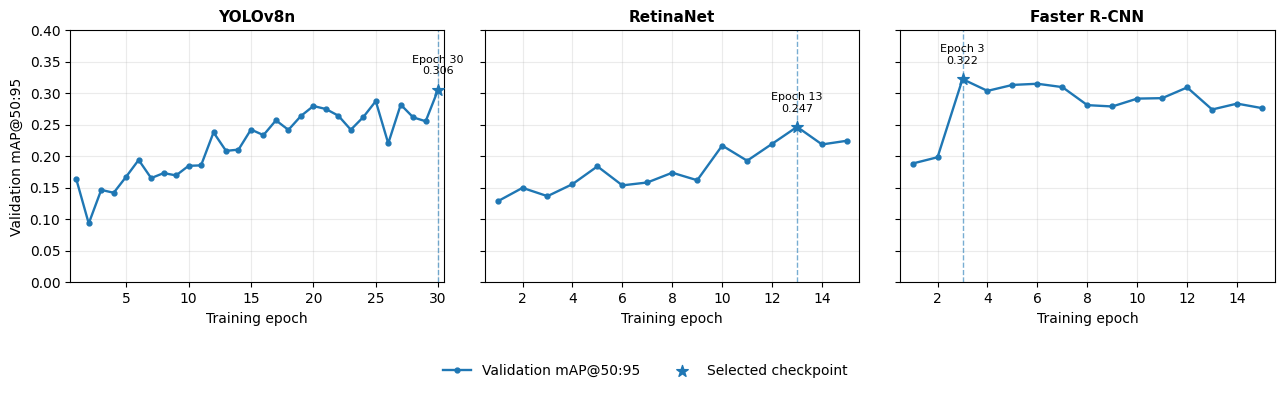

Figure saved:
/content/gdrive_new/MyDrive/MMA3001_Project/comparison_results/report_figures/figure_4_3_1_validation_history.png
/content/gdrive_new/MyDrive/MMA3001_Project/comparison_results/report_figures/figure_4_3_1_validation_history.pdf


In [ ]:

# ============================================================
# FIGURE 4.3.1 — VALIDATION mAP@50:95 DURING TRAINING
#
# Compares the final four-class training runs.
# Highlights the selected checkpoint for each model.
#
# Reads saved training logs — no retraining required.
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import torch

# ------------------------------------------------------------
# 1. Project directories
# ------------------------------------------------------------

REPORT_DIR = (
    PROJECT_ROOT / "comparison_results" / "report_figures"
)
REPORT_DIR.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# 2. Paths to the three final four-class runs
# ------------------------------------------------------------
RUN_CONFIG = {
    "YOLOv8n": {
        "history": (
            RUNS_ROOT
            / "yolov8n_4class_30epochs"
            / "results.csv"
        ),
        "checkpoint": (
            RUNS_ROOT
            / "yolov8n_4class_30epochs"
            / "weights"
            / "best.pt"
        ),
        "format": "ultralytics"
    },
    "RetinaNet": {
        "history": (
            RUNS_ROOT
            / "retinanet_resnet50_4class"
            / "training_history.csv"
        ),
        "checkpoint": (
            RUNS_ROOT
            / "retinanet_resnet50_4class"
            / "best.pt"
        ),
        "format": "torchvision"
    },
    "Faster R-CNN": {
        "history": (
            RUNS_ROOT
            / "faster_rcnn_resnet50_4class"
            / "training_history.csv"
        ),
        "checkpoint": (
            RUNS_ROOT
            / "faster_rcnn_resnet50_4class"
            / "best.pt"
        ),
        "format": "torchvision"
    }
}

# ------------------------------------------------------------
# 3. Check saved logs and checkpoints
# ------------------------------------------------------------
print("Checking training files:\n")

for name, config in RUN_CONFIG.items():
    print(name)
    print(" History:", config["history"].exists())
    print(" Checkpoint:", config["checkpoint"].exists())

    if not config["history"].exists():
        print(" Expected history:", config["history"])

        # Help locate the correct saved log.
        matches = sorted(
            RUNS_ROOT.rglob("training_history.csv")
        ) if config["format"] == "torchvision" else sorted(
            RUNS_ROOT.rglob("results.csv")
        )

        print(" Available candidate files:")
        for p in matches[:20]:
            print("  ", p)

    print()

# Stop rather than silently plotting the wrong run.
missing = [
    name
    for name, config in RUN_CONFIG.items()
    if not config["history"].exists()
]

if missing:
    raise FileNotFoundError(
        f"Missing training logs for: {missing}. "
        "Update RUN_CONFIG using the paths printed above."
    )

# ------------------------------------------------------------
# 4. Load and standardise training histories
# ------------------------------------------------------------

def load_training_history(config):
    """
    Load and standardise validation training history
    for YOLOv8n, RetinaNet, and Faster R-CNN.

    Returns:
        DataFrame with columns:
        - epoch
        - map5095
    """
    df = pd.read_csv(config["history"])
    df.columns = df.columns.str.strip()

    # Ultralytics uses its own metric naming convention
    if config["format"] == "ultralytics":
        epoch_col = "epoch"
        metric_col = "metrics/mAP50-95(B)"

    else:
        # Support different Torchvision training log formats
        epoch_candidates = ["epoch", "Epoch"]

        metric_candidates = [
            "val_map5095",
            "Val_mAP50_95",
            "val_map50_95",
            "Val_mAP50:95",
            "val_map",
            "map5095",
            "map"
        ]

        epoch_col = next(
            (col for col in epoch_candidates if col in df.columns),
            None
        )

        metric_col = next(
            (col for col in metric_candidates if col in df.columns),
            None
        )

    if epoch_col is None or metric_col is None:
        raise KeyError(
            "Unable to identify training columns.\n"
            f"Available columns: {list(df.columns)}"
        )

    epochs = pd.to_numeric(df[epoch_col])
    values = pd.to_numeric(df[metric_col])

    # Adjust zero-based epoch numbering if necessary
    if epochs.min() == 0:
        epochs = epochs + 1

    return pd.DataFrame({
        "epoch": epochs.astype(int),
        "map5095": values
    }).dropna()


# ------------------------------------------------------------
# 5. Read each model's selected checkpoint epoch
# ------------------------------------------------------------
def get_selected_epoch(config, history):
    """
    Return the selected checkpoint epoch.

    For Torchvision, use the epoch recorded in best.pt.
    For YOLO, infer the epoch with the highest logged
    validation mAP@50:95 (used for verification).
    """
    if config["format"] == "ultralytics":
        idx = history["map5095"].idxmax()
        return int(history.loc[idx, "epoch"])

    if config["checkpoint"].exists():
        checkpoint = torch.load(
            config["checkpoint"],
            map_location="cpu",
            weights_only=False
        )

        if "epoch" in checkpoint:
            return int(checkpoint["epoch"])

    # Fallback: maximum validation metric
    idx = history["map5095"].idxmax()
    return int(history.loc[idx, "epoch"])


histories = {}
selection_rows = []

for name, config in RUN_CONFIG.items():

    history = load_training_history(config)
    selected_epoch = get_selected_epoch(config, history)

    selected_record = history.loc[
        history["epoch"] == selected_epoch
    ]

    if selected_record.empty:
        raise ValueError(
            f"{name}: selected epoch {selected_epoch} "
            "is not present in the training history. "
            "Check whether epoch numbering is zero-based."
        )

    selected_map = float(
        selected_record["map5095"].iloc[0]
    )

    histories[name] = {
        "history": history,
        "epoch": selected_epoch,
        "map": selected_map
    }

    selection_rows.append({
        "Model": name,
        "Total_Epochs": int(history["epoch"].max()),
        "Selected_Epoch": selected_epoch,
        "Checkpoint_Validation_mAP5095": selected_map
    })

selection_df = pd.DataFrame(selection_rows)

print("\nCHECKPOINT SELECTION SUMMARY")
display(selection_df.round(4))

# ------------------------------------------------------------
# 6. Create a three-panel academic figure
# ------------------------------------------------------------
fig, axes = plt.subplots(
    1, 3,
    figsize=(13, 3.8),
    sharey=True
)

for ax, (name, result) in zip(axes, histories.items()):

    history = result["history"]
    selected_epoch = result["epoch"]
    selected_map = result["map"]

    # Validation trajectory
    ax.plot(
        history["epoch"],
        history["map5095"],
        marker="o",
        markersize=3.5,
        linewidth=1.7,
        label="Validation mAP@50:95"
    )

    # Highlight selected checkpoint
    ax.scatter(
        selected_epoch,
        selected_map,
        s=75,
        marker="*",
        zorder=5,
        label="Selected checkpoint"
    )

    ax.axvline(
        selected_epoch,
        linestyle="--",
        linewidth=1,
        alpha=0.6
    )

    ax.annotate(
        f"Epoch {selected_epoch}\n{selected_map:.3f}",
        xy=(selected_epoch, selected_map),
        xytext=(0, 11),
        textcoords="offset points",
        fontsize=8,
        ha="center"
    )

    ax.set_title(name, fontsize=11, fontweight="bold")
    ax.set_xlabel("Training epoch")
    ax.grid(alpha=0.25)

    ax.set_xlim(
        0.5,
        max(history["epoch"].max() + 0.5, 2)
    )

axes[0].set_ylabel("Validation mAP@50:95")

# Shared y-axis scale for fair visual comparison
all_scores = np.concatenate([
    item["history"]["map5095"].to_numpy()
    for item in histories.values()
])
axes[0].set_ylim(0, max(0.4, all_scores.max() * 1.15))

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(
    handles,
    labels,
    loc="lower center",
    bbox_to_anchor=(0.5, -0.04),
    ncol=2,
    frameon=False
)

fig.tight_layout(rect=[0, 0.09, 1, 1])

# ------------------------------------------------------------
# 7. Export figure
# ------------------------------------------------------------
png_path = REPORT_DIR / "figure_4_3_1_validation_history.png"
pdf_path = REPORT_DIR / "figure_4_3_1_validation_history.pdf"

fig.savefig(
    png_path,
    dpi=300,
    bbox_inches="tight"
)

fig.savefig(
    pdf_path,
    bbox_inches="tight"
)

plt.show()

print("Figure saved:")
print(png_path)
print(pdf_path)
